<a href="https://colab.research.google.com/github/vidhis1612/Python/blob/main/MinorProject2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("AB_NYC_2019.csv")

In [3]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.shape

(48895, 16)

In [5]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [7]:
df.columns.tolist()

['id',
 'name',
 'host_id',
 'host_name',
 'neighbourhood_group',
 'neighbourhood',
 'latitude',
 'longitude',
 'room_type',
 'price',
 'minimum_nights',
 'number_of_reviews',
 'last_review',
 'reviews_per_month',
 'calculated_host_listings_count',
 'availability_365']

In [9]:
df.dtypes

,0
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


In [10]:
# Numerical values
df.select_dtypes(include=np.number).columns.tolist()

['id',
 'host_id',
 'latitude',
 'longitude',
 'price',
 'minimum_nights',
 'number_of_reviews',
 'reviews_per_month',
 'calculated_host_listings_count',
 'availability_365']

In [11]:
# Categorical values
df.select_dtypes(include="object").columns.tolist()

['name',
 'host_name',
 'neighbourhood_group',
 'neighbourhood',
 'room_type',
 'last_review']

In [12]:
# Missing values and percentages
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing)

print("Duplicate rows:", df.duplicated().sum())

,Missing Count,Missing Percentage
id,0,0.00
name,16,0.03
host_id,0,0.00
host_name,21,0.04
neighbourhood_group,0,0.00
neighbourhood,0,0.00
latitude,0,0.00
longitude,0,0.00
room_type,0,0.00
price,0,0.00


Duplicate rows: 0


Data Cleaning

In [13]:
df_clean = df.copy()

In [14]:
df_clean.shape

(48895, 16)

In [15]:
# Remove latest_review
# 1. It has many values and is not needed
# 2. for the selected regression features.
df_clean.drop(columns=["last_review"], inplace=True)

In [17]:
# Investigate missing reviews_per_month
missing_reviews = df_clean[
    df_clean["reviews_per_month"].isna()
]

print("Missing reviews_per_month:",
      len(missing_reviews))
print("Number of reviews for these rows:")
print(missing_reviews["number_of_reviews"].value_counts().head(10))

Missing reviews_per_month: 10052

Number of reviews for these rows:
number_of_reviews
0    10052
Name: count, dtype: int64


In [18]:
# Zero reviews means no recorded review frequency.
zero_review_mask = (
    df_clean["reviews_per_month"].isna()
    & (df_clean["number_of_reviews"] == 0)
)

df_clean.loc[zero_review_mask, "reviews_per_month"] = 0

In [19]:
# If other missing values remain, investigate them.
print("Remaining missing review rates:")
print(df_clean["reviews_per_month"].isna().sum())



Remaining missing review rates:
0


In [20]:
# Remove irrelevant text and identifiers
drop_columns = [
    "id",
    "name",
    "host_id",
    "host_name"
]

df_clean.drop(columns=drop_columns, inplace=True)


In [21]:
# Remove duplicate records
df_clean.drop_duplicates(inplace=True)

print("Cleaned Dataset Shape:", df_clean.shape)
print("Remaining Missing Values:")
print(df_clean.isnull().sum())



Cleaned Dataset Shape: (48895, 11)

Remaining Missing Values:
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64


OUTLIER IDENTIFICATION

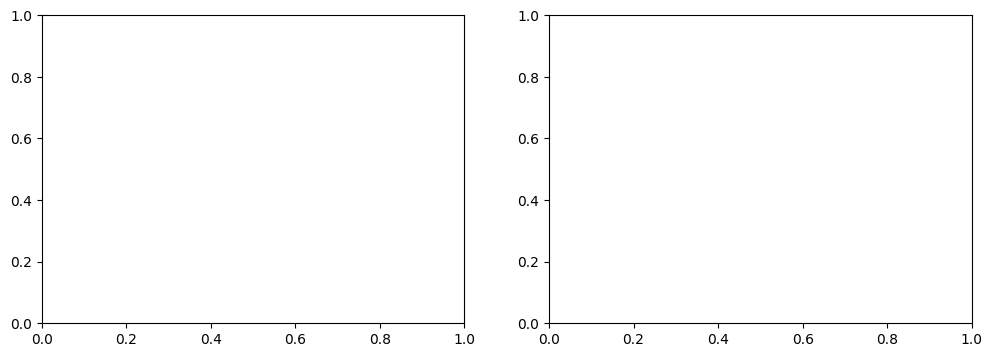

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

In [23]:
sns.boxplot(x=df_clean["price"], ax=axes[0])
axes[0].set_title("Airbnb Price Outliers")
axes[0].set_xlabel("Price ($)")

Text(0.5, 4.444444444444445, 'Price ($)')

In [24]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [25]:
# Keep valid positive values
df_clean = df_clean[
    (df_clean["price"] > 0) &
    (df_clean["minimum_nights"] > 0)
].copy()

In [26]:
# 95th percentile thresholds
price_limit = df_clean["price"].quantile(0.95)
nights_limit = df_clean["minimum_nights"].quantile(0.95)

print("95th Percentile Price:", price_limit)
print("95th Percentile Minimum Nights:", nights_limit)

before_rows = len(df_clean)


95th Percentile Price: 355.0
95th Percentile Minimum Nights: 30.0


In [28]:
# Trim extreme records
df_clean = df_clean[
    (df_clean["price"] <= price_limit) &
    (df_clean["minimum_nights"] <= nights_limit)
].copy()
print("Rows Before Trimming:", before_rows)
print("Rows After Trimming:", len(df_clean))
print("Rows Removed:", before_rows - len(df_clean))

Rows Before Trimming: 48884
Rows After Trimming: 45748
Rows Removed: 3136


FEATURE SELECTION AND ENCODING

In [29]:
print("Unique Neighbourhoods:",
      df_clean["neighbourhood"].nunique())

Unique Neighbourhoods: 219


In [30]:
print("Unique Neighbourhood Groups:",
      df_clean["neighbourhood_group"].nunique())


Unique Neighbourhood Groups: 5


In [31]:
# Drop neighbourhood because it has many categories
df_clean.drop(columns=["neighbourhood"], inplace=True)


In [32]:
# Encode the remaining categorical variables
df_encoded = pd.get_dummies(
    df_clean,
    columns=["neighbourhood_group", "room_type"],
    drop_first=True,
    dtype=int
)

print("Encoded Dataset Shape:", df_encoded.shape)
display(df_encoded.head())

print("Remaining Missing Values:")
print(df_encoded.isnull().sum())


Encoded Dataset Shape: (45748, 14)


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0


Remaining Missing Values:
latitude                             0
longitude                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
neighbourhood_group_Brooklyn         0
neighbourhood_group_Manhattan        0
neighbourhood_group_Queens           0
neighbourhood_group_Staten Island    0
room_type_Private room               0
room_type_Shared room                0
dtype: int64


FEATURE-TARGET SEPARATION

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
X = df_encoded.drop(columns=["price"])
y = df_encoded["price"]


In [36]:
# Use only complete numeric records
valid_rows = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (36598, 13)
Testing Features: (9150, 13)
Training Target: (36598,)
Testing Target: (9150,)


 LINEAR REGRESSION

In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [38]:
# Train model
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [39]:
# Predict on test data
y_pred = model.predict(X_test)


In [41]:
# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("MODEL EVALUATION")
print(f"R-Squared: {r2:.4f}")
print(f"MAE: ${mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: ${rmse:.2f}")


MODEL EVALUATION
R-Squared: 0.4868
MAE: $38.32
MSE: 2760.62
RMSE: $52.54


RESIDUAL ANALYSIS

In [42]:
residuals = y_test - y_pred

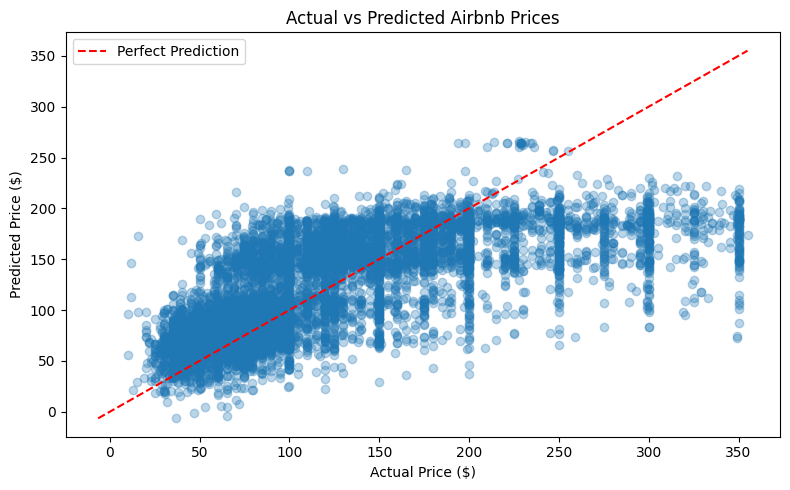

In [43]:
# Actual vs Predicted
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.3)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot(
    [low, high],
    [low, high],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Airbnb Prices")
plt.legend()
plt.tight_layout()
plt.show()


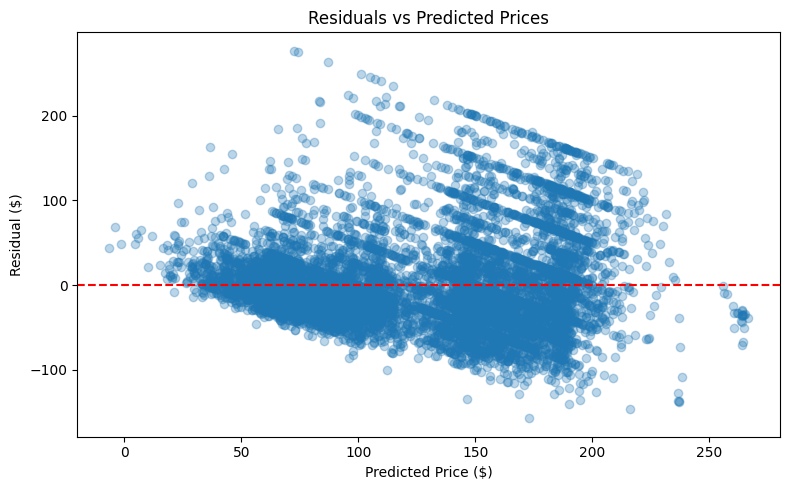

In [44]:
# Residual plot
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residuals vs Predicted Prices")
plt.tight_layout()
plt.show()

In [45]:
# Compare cheap and expensive listings
median_price = y_test.median()

cheap_mask = y_test <= median_price
expensive_mask = y_test > median_price

cheap_mae = mean_absolute_error(
    y_test[cheap_mask],
    y_pred[cheap_mask]
)

expensive_mae = mean_absolute_error(
    y_test[expensive_mask],
    y_pred[expensive_mask]
)

print(f"Cheap Listings MAE: ${cheap_mae:.2f}")
print(f"Expensive Listings MAE: ${expensive_mae:.2f}")

if cheap_mae < expensive_mae:
    print("Lower absolute errors for cheaper listings.")
elif expensive_mae < cheap_mae:
    print("Lower absolute errors for expensive listings.")
else:
    print("Both groups have equal MAE.")


Cheap Listings MAE: $29.01
Expensive Listings MAE: $48.18
Lower absolute errors for cheaper listings.
